In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import tensorflow as tf
tf.random.set_seed(2025)
np.random.seed(2025)


In [2]:
tf.__version__

'2.20.0'

In [3]:
np.random.seed(2025)
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
X_train_full.max(),X_train_full.min()

(np.uint8(255), np.uint8(0))

In [5]:
# Normalizing
X_train_full = (X_train_full/255.).astype('float32')
y_train_full = y_train_full.astype('int32')
np.unique(y_train_full)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int32)

In [6]:
# Test
X_test = (X_test/255.).astype('float32')
y_test = y_test.astype('int32')

In [7]:
X_train_full.shape

(60000, 28, 28)

In [8]:
# Split train to train & valid
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full,
                                                      test_size=0.1, shuffle=True, stratify=y_train_full)
print('X_train Shape => ', X_train.shape)
print('y_train Shape => ', y_train.shape)

print('----'*10)

print('X_val Shape => ', X_valid.shape)
print('y_val Shape => ', y_valid.shape)

print('----'*10)

print('X_test Shape => ', X_test.shape)
print('y_test Shape => ', y_test.shape)

X_train Shape =>  (54000, 28, 28)
y_train Shape =>  (54000,)
----------------------------------------
X_val Shape =>  (6000, 28, 28)
y_val Shape =>  (6000,)
----------------------------------------
X_test Shape =>  (10000, 28, 28)
y_test Shape =>  (10000,)


<function matplotlib.pyplot.show(close=None, block=None)>

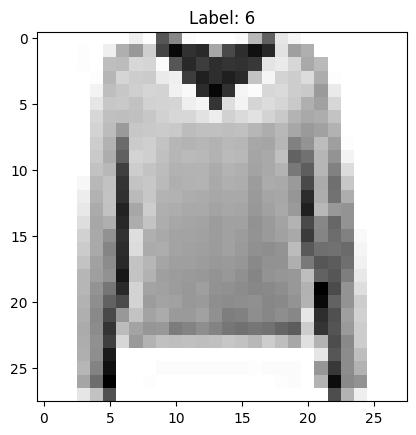

In [9]:
# Flatten
# About Target
plt.imshow(X_train[0], cmap='binary')
plt.title(f"Label: {y_train[0]}")
plt.show

In [10]:
target_only_plot = pd.DataFrame(y_train, columns=['target'])
target_only_plot

,target
0,6
1,2
2,2
3,3
4,0
...,...
53995,2
53996,7
53997,4
53998,6


In [11]:
# Get One Unique Label With Its Index In Dataset
# Get First Unique Value Only, What This Number Belong To What Photo
img_indicies = {}  # label: index
for i in range(len(np.unique(y_train))):
  img_indicies[i] = target_only_plot[target_only_plot['target'] == i].index[0]


img_indicies


{0: np.int64(4),
 1: np.int64(8),
 2: np.int64(1),
 3: np.int64(3),
 4: np.int64(5),
 5: np.int64(10),
 6: np.int64(0),
 7: np.int64(6),
 8: np.int64(14),
 9: np.int64(20)}

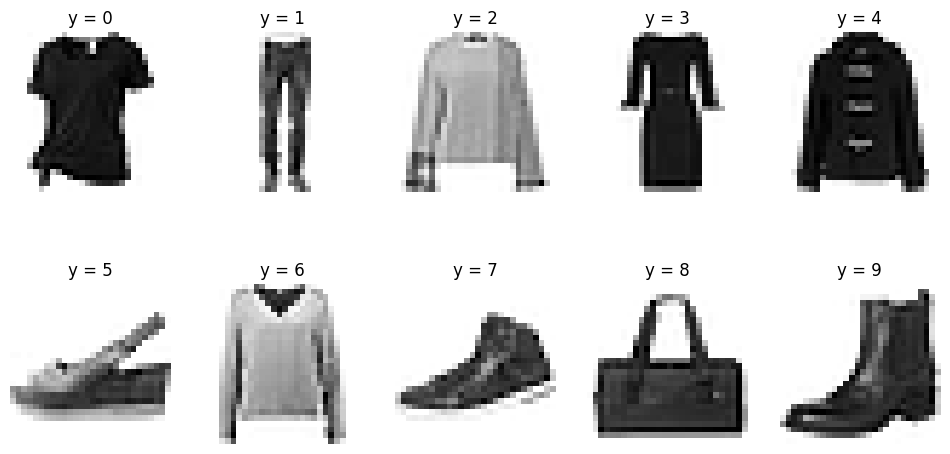

In [12]:
# Plotting
fig, ax = plt.subplots(2, 5, figsize=(12, 6))

keys = list(img_indicies.keys())

label = 0
for row in range(2):
  for col in range(5):
    plt.sca(ax[row, col])
    plt.imshow(X_train[img_indicies[label]], cmap='binary')
    plt.title(f"y = {keys[label]}", fontsize=12, c='k')
    plt.axis('off')
    label += 1

In [13]:
# You Can Now Know For Each Target Value Belong To What Class
class_names = ['T_shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle_Boot']



In [14]:
X_train.shape, y_train.shape

((54000, 28, 28), (54000,))

In [15]:
# Build A Model
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(units=128, activation='relu', kernel_initializer='glorot_normal'),
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=32, activation='relu'),
    # Output Layer
    tf.keras.layers.Dense(units=10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
w, b = model.layers[1].get_weights()

<Axes: >

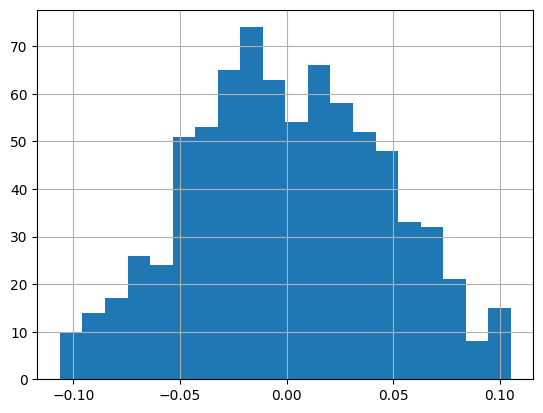

In [17]:
pd.DataFrame(w).iloc[:, 5].hist(bins=20)

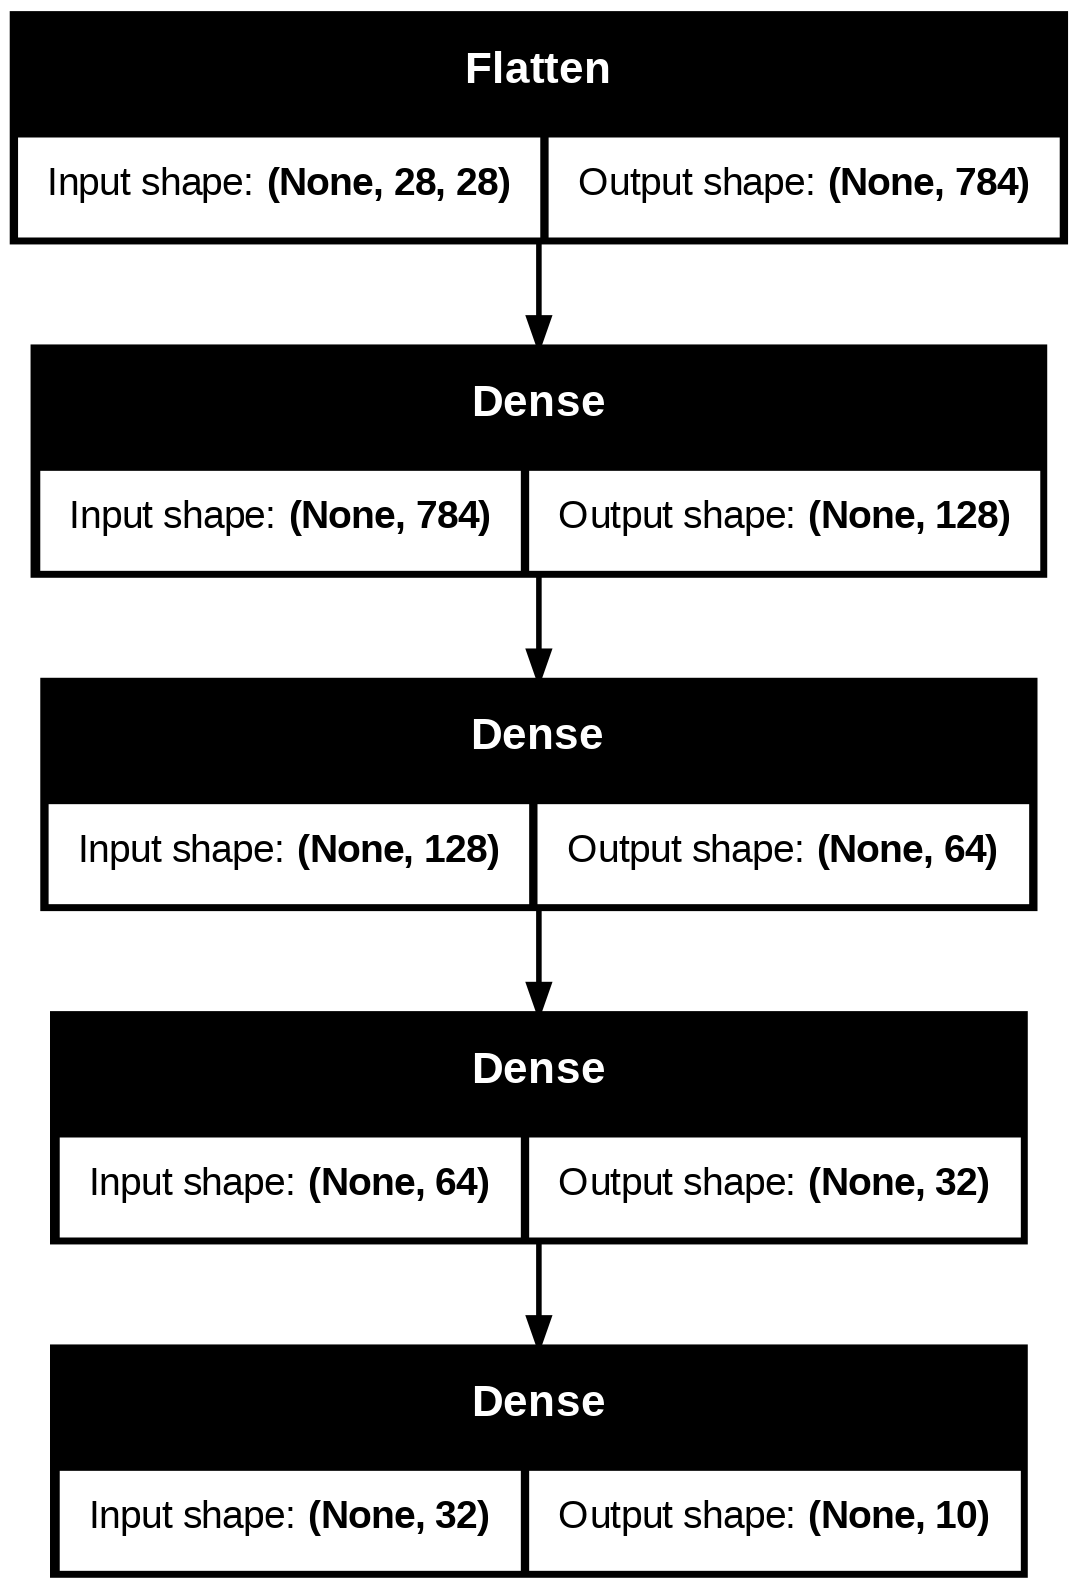

In [18]:
# Plot The Model
tf.keras.utils.plot_model(model, show_shapes=True)

In [19]:
# categorical_crossentropy
# binary_crossentropy
# sparse_categorical_crossentropy --> Target (1D) without ohe

In [20]:
from sklearn import metrics
# Compile
model.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = tf.keras.optimizers.SGD(learning_rate=.01),  # SGD
    metrics=['accuracy']
)

In [21]:
# Callbacks
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# train
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.7272 - loss: 0.8084 - val_accuracy: 0.8087 - val_loss: 0.5514
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.8219 - loss: 0.5010 - val_accuracy: 0.8318 - val_loss: 0.4836
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8413 - loss: 0.4478 - val_accuracy: 0.8423 - val_loss: 0.4520
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8528 - loss: 0.4173 - val_accuracy: 0.8478 - val_loss: 0.4294
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8596 - loss: 0.3955 - val_accuracy: 0.8510 - val_loss: 0.4163
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8654 - loss: 0.3782 - val_accuracy: 0.8568 - val_loss: 0.3978
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8707 - loss: 0.3639 - val_accuracy: 0.8647 - val_loss: 0.3799
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8741 - loss: 0.3515

In [22]:
history.history

{'accuracy': [0.7271666526794434,
  0.8218703866004944,
  0.8412963151931763,
  0.8527777791023254,
  0.8595740795135498,
  0.865407407283783,
  0.8707407116889954,
  0.8741481304168701,
  0.8776296377182007,
  0.8809999823570251,
  0.8846296072006226,
  0.8865370154380798,
  0.8897963166236877,
  0.8918333053588867,
  0.8935925960540771,
  0.895203709602356,
  0.8976110816001892,
  0.8996852040290833,
  0.9017037153244019,
  0.9035184979438782,
  0.9053888916969299,
  0.9075000286102295,
  0.9088147878646851,
  0.9104629755020142,
  0.9125000238418579,
  0.9138888716697693,
  0.9152592420578003,
  0.9165740609169006,
  0.9176296591758728,
  0.9198333621025085],
 'loss': [0.8083984851837158,
  0.500980794429779,
  0.4478495121002197,
  0.4172949492931366,
  0.3954724371433258,
  0.3782254755496979,
  0.36386051774024963,
  0.35150718688964844,
  0.340797483921051,
  0.3312284052371979,
  0.3226170837879181,
  0.3146280348300934,
  0.30704939365386963,
  0.3002207577228546,
  0.29364269

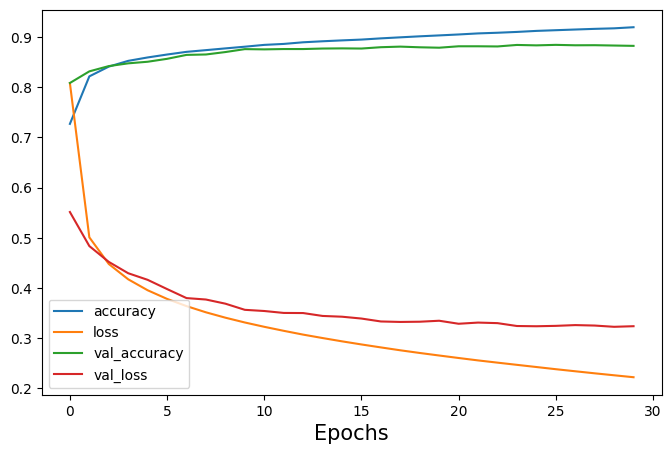

In [23]:
# Plotting History Results
history_info = history.history
pd.DataFrame(history_info).plot(figsize=(8, 5))
plt.xlabel('Epochs', fontsize=15)
plt.legend(loc='lower left')
plt.show()

In [24]:
# Dump Model
model.save('model.keras')

In [25]:
# load a pretrained model
model = tf.keras.models.load_model('model.keras')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,148 (434.18 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [26]:
# Simulate Real Time
X_new = X_test[:3]
y_new = y_test[:3]


y_pred_new = np.argmax(model.predict(X_new), axis=-1)
print('Predicted Labels: ', y_pred_new)
print()

# To Get Thier Class_Names
y_pred_names = [class_names[pred] for pred in y_pred_new]
print(y_pred_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step
Predicted Labels:  [9 2 1]

['Ankle_Boot', 'Pullover', 'Trouser']


In [ ]:
import os
from PIL import Image


In [28]:
## Download Some Images To Test Model
# for i, img_array in enumerate(X_test[:3]):
#   img_array = (img_array * 255).astype(np.uint8)
#   img = Image.fromarray(img_array)
#   output_path = os.path.join(".", f"test_image_{i}.png")
#   img.save(output_path)

In [29]:
def inference(image_path: str):
  img = Image.open(image_path)

  # Same Preprocessing We Trained on
  img.resize(28, 28)
  img = np.array(img)

  # u need To Add Batch Size (expand dimension)
  img_array = img_array.astype('float32') / 255.0
  img_array = np.expand_dims(img_array, axis=0)

  prediction = model.predict(img_array, verbose=2)
  predicted_class = np.argmax(prediction, axis=-1)[0]
  predicted_name = class_names[predicted_class]

  return {
      'class_index': int(predicted_class),
      'class_name': predicted_name,
      'confidence': float(prediction[0][predicted_class] * 100)

  }


In [35]:
import numpy as np
from PIL import Image

def inference(image_path: str):
    # 1. فتح الصورة وتحويلها (مثلاً لـ Grayscale لو موديل زي MNIST)
    img = Image.open(image_path).convert('L')

    # 2. تغيير الحجم بحجم tuple وتخزين الناتج
    img = img.resize((28, 28))

    # 3. تحويلها لـ NumPy array
    img_array = np.array(img)

    # 4. التطهير والـ Normalization إضافة أبعاد الـ Batch
    img_array = img_array.astype('float32') / 255.0
    img_array = np.expand_dims(img_array, axis=0) # الشكل هيبقي (1, 28, 28)

    # 5. التوقع
    prediction = model.predict(img_array, verbose=0)
    predicted_class = np.argmax(prediction, axis=-1)[0]
    predicted_name = class_names[predicted_class]

    return {
        'class_index': int(predicted_class),
        'class_name': predicted_name,
        'confidence': float(prediction[0][predicted_class] * 100)
    }


In [36]:
inference("/content/test_image_1.png")

{'class_index': 2, 'class_name': 'Pullover', 'confidence': 99.68781280517578}